In [3]:
# install pandas
%pip install pandas


Note: you may need to restart the kernel to use updated packages.


In [4]:
# ============================================================
# AI-Assisted Network Anomaly Detection
# Step 1: Load the network traffic dataset
# ============================================================

# Import pandas to load and analyze the CSV dataset.
import pandas as pd
# Load the feature dataset exported from the Ubuntu sensor VM.
df = pd.read_csv(
    r"C:\Users\dzsam\Downloads\windows_vm_dataset (1).csv"
)

# Display the first 5 rows to verify that the dataset loaded correctly.
display(df.head())


,minute,device_ip,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
0,9/17/2026 1:40,192.168.50.10,176,45842,260.465909,163,13,10,2,13
1,10/4/2026 0:49,192.168.50.10,599,140018,233.752922,582,17,31,3,5
2,10/4/2026 0:50,192.168.50.10,936,894425,955.582265,924,12,57,3,6
3,10/4/2026 0:51,192.168.50.10,816,296069,362.829657,793,23,75,4,21
4,10/4/2026 0:52,192.168.50.10,647,291583,450.669243,616,27,77,3,11


In [5]:

# ============================================================
# Step 2: Inspect the network traffic dataset
# ============================================================

# Display the number of rows and columns in the dataset.
# Each row represents one minute of traffic from the Windows VM.
print("Dataset shape:", df.shape)

# Display the names of the dataset columns.
print("\nColumn names:")
print(df.columns.tolist())

# Check each column's data type and identify missing values.
print("\nDataset information:")
df.info()

# Display summary statistics for the numerical columns.
# This helps us understand the range and variation of network traffic.
print("\nSummary statistics:")
display(df.describe())


Dataset shape: (170, 10)

Column names:
['minute', 'device_ip', 'packet_count', 'total_bytes', 'average_packet_size', 'tcp_count', 'udp_count', 'unique_destinations', 'unique_ports', 'dns_count']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   minute               170 non-null    str    
 1   device_ip            170 non-null    str    
 2   packet_count         170 non-null    int64  
 3   total_bytes          170 non-null    int64  
 4   average_packet_size  170 non-null    float64
 5   tcp_count            170 non-null    int64  
 6   udp_count            170 non-null    int64  
 7   unique_destinations  170 non-null    int64  
 8   unique_ports         170 non-null    int64  
 9   dns_count            170 non-null    int64  
dtypes: float64(1), int64(7), str(2)
memory usage: 13.4 KB

Summary statistics:


,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
count,170.000000,1.700000e+02,170.000000,170.000000,170.000000,170.000000,170.000000,170.000000
mean,642.235294,2.296021e+05,355.783159,617.088235,24.870588,45.235294,2.376471,3.323529
std,471.642871,2.882215e+05,261.462277,449.387734,48.105355,55.947174,1.254355,7.391506
min,6.000000,6.000000e+02,60.000000,6.000000,0.000000,1.000000,1.000000,0.000000
25%,240.750000,5.290100e+04,71.828708,236.500000,0.000000,8.500000,1.000000,0.000000
50%,470.000000,1.163235e+05,358.289968,468.500000,5.000000,24.000000,2.000000,0.000000
75%,1046.500000,2.891465e+05,541.564728,1010.000000,27.000000,61.750000,3.000000,3.000000
max,1973.000000,1.394261e+06,1073.552752,1881.000000,392.000000,298.000000,8.000000,54.000000


In [6]:
# ===========================================================
# Step 3: Prepare the numerical features for machine learning
# ===========================================================

# Import NumPy for numerical operations.
import numpy as np

# Select the eight numerical traffic features.
# We exclude the timestamp and device IP because they identify.
# each record rather than measure traffic behavior

feature_columns = [
    "packet_count",
    "total_bytes",
    "average_packet_size",
    "tcp_count",
    "udp_count",
    "unique_destinations",
    "unique_ports",
    "dns_count"
]

# Create a seperate DataFrame containing only the model featueres
X = df[feature_columns].copy()

# Convert all selected features to numeric values.
# Invalid values will become missiing values(NaN).
X = X.apply(pd.to_numeric, errors="coerce")

# Check for missing or infinite values before training.
X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X.shape)
print("Missing values per feature:")
print(X.isnull().sum())

# Stop if any missing or infinite values need to be handled.
if X.isnull().any().any():
    raise ValueError("Missing or invalid values found. Clean the data before training")

# Display the first five rows of prepared feature matrix.
display(X.head())
 

Feature matrix shape: (170, 8)
Missing values per feature:
packet_count           0
total_bytes            0
average_packet_size    0
tcp_count              0
udp_count              0
unique_destinations    0
unique_ports           0
dns_count              0
dtype: int64


,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
0,176,45842,260.465909,163,13,10,2,13
1,599,140018,233.752922,582,17,31,3,5
2,936,894425,955.582265,924,12,57,3,6
3,816,296069,362.829657,793,23,75,4,21
4,647,291583,450.669243,616,27,77,3,11


In [7]:
# =================================================
# Step 4: Split the dataset chronologically
# =================================================


# Calculate the index separating the first 80% from the final 20%
# The dataset is already ordered by minute when it was exported

split_index = int(len(X) * 0.80) 

# Use the earlier 80% of records to train the model.
X_train = X.iloc[:split_index].copy()

# Reserve the later 20% to test the model on unseen records.
X_test = X.iloc[split_index:].copy()

# Keep the timestamps so we can identify when anomalies occur.
test_timestamps = df["minute"].iloc[split_index:].reset_index(drop=True)



In [8]:
# ============================================================
# Step 5A: Install the machine learning library
# ============================================================

# Install scikit-learn, which provides the Isolation Forest model.
# The %pip command installs it into the notebook's active environment.
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
# Step 5B: Train the Isolation Forest anomaly detection model
# ===========================================================

# Import Isolation Forest, an unsupervised machine learning algorithm
from sklearn.ensemble import IsolationForest

# Create the model.
# n_estimators=100 means the model uses 100 decision trees.
# contamination="auto" lets the algorithm use its default threshold.
# for deciding which records appear unusual.
# random_state=42 makes results reproducible between runs.

model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42
)

# Train the model using only the first 80% of the traffic.
# The model learns patterns from, these earlier records.

model.fit(X_train)

# Confirm the training completed.
print("Isolation Forest model trained successfully.")
print("Training records used:", len(X_train))



Isolation Forest model trained successfully.
Training records used: 136


In [10]:
# ===============================================
# Step 6: Detect anomalies in the testing dataset
# ===============================================

# Ask the trained model to classify the testing records.
# The model returns:
# 1 = normal traffic
#-1 = potentially anomalous traffic

predictions = model.predict(X_test)

# Calculate an anomaly score for each testing record.
# Lower scores indicate records that appear more unusual.

anomaly_scores = model.decision_function(X_test)

# Display how many records were tested.
print("Testing records used:", len(X_test))

# Count the record classified as normal.
print("Normal records:", (predictions == 1).sum())

# Count the records classified as anomalies.
print("Potential anomalies:", (predictions == -1).sum())




Testing records used: 34
Normal records: 33
Potential anomalies: 1


In [11]:
# ============================================================
# Step 7: Display the records flagged as potential anomalies
# ============================================================

# Copy the testing records so we don't modify the original data.
results = X_test.copy()

# Attach the timestamps of the testing records.
results["minute"] = test_timestamps.values

# Attach the Windows VM's IP address.
results["device_ip"] = df["device_ip"].iloc[split_index:].values

# Store the model's predictions.
results["prediction"] = predictions

# Store the anomaly scores.
results["anomaly_scores"] = anomaly_scores

# Select only records that the model flagged as anomalies.
anomalies = results[results["prediction"] == -1]

# Display the flagged records for investigation.
display(anomalies)

,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count,minute,device_ip,prediction,anomaly_scores
150,187,164930,881.97861,179,8,12,1,0,10/6/2026 19:35,192.168.50.10,-1,-0.012714


In [12]:
# ============================================================
# Step 8: Examine the traffic features flagged as anomalous
# ============================================================

# Display only the numerical features used by the model.
# This lets us focus on the traffic characteristics.
display(anomalies[feature_columns])

,packet_count,total_bytes,average_packet_size,tcp_count,udp_count,unique_destinations,unique_ports,dns_count
150,187,164930,881.97861,179,8,12,1,0


In [13]:
# ===============================================
# Step 9: Examine the training data baseline
# ===============================================

# Calculate descriptive statistics for each traiffic
# These statistics help us understand the typical traffic pattern
# in the data used to train our model.

baseline_stats = X_train.describe(
    percentiles=[0.50, 0.95, 0.99]
).T

# Display the statistics for all eight traffic features.
display(baseline_stats)

,count,mean,std,min,50%,95%,99%,max
packet_count,136.0,741.183824,472.460293,6.0,744.000000,1530.250000,1.764050e+03,1.973000e+03
total_bytes,136.0,266401.882353,307432.000416,600.0,143609.500000,927644.000000,1.314417e+06,1.394261e+06
average_packet_size,136.0,359.847519,253.159142,60.0,368.195893,790.043101,9.624243e+02,9.846456e+02
tcp_count,136.0,710.382353,450.657907,6.0,696.000000,1416.000000,1.732000e+03,1.881000e+03
udp_count,136.0,30.514706,52.269669,0.0,11.500000,132.500000,2.098000e+02,3.920000e+02
unique_destinations,136.0,52.779412,59.983293,2.0,27.000000,196.250000,2.499000e+02,2.980000e+02
unique_ports,136.0,2.507353,1.322155,1.0,2.000000,5.000000,5.650000e+00,8.000000e+00
dns_count,136.0,3.919118,8.071032,0.0,0.000000,21.500000,2.965000e+01,5.400000e+01


In [14]:
# ============================================================
# Step 10: Compare the flagged record with training statistics
# ============================================================

# Extract the single flagged record's numerical feature
flagged_values = anomalies[feature_columns].iloc[0]

# Calculate how far each flagged values is from its training mean.
# Dvide by the standard deviation to make the comparison easier.
comparison = pd.DataFrame({
    "flagged_value": flagged_values,
    "training_mean": X_train.mean(),
    "training_std" : X_train.std()
})

# Calculate the diference in standard deviation units.
comparison["standard_deviations_from_mean"] = (
    (comparison["flagged_value"] - comparison["training_mean"])
    / comparison["training_std"]
)
# Display the comparison.
display(comparison)


,flagged_value,training_mean,training_std,standard_deviations_from_mean
packet_count,187.00000,741.183824,472.460293,-1.172974
total_bytes,164930.00000,266401.882353,307432.000416,-0.330063
average_packet_size,881.97861,359.847519,253.159142,2.062462
tcp_count,179.00000,710.382353,450.657907,-1.179126
udp_count,8.00000,30.514706,52.269669,-0.430741
unique_destinations,12.00000,52.779412,59.983293,-0.679846
unique_ports,1.00000,2.507353,1.322155,-1.140073
dns_count,0.00000,3.919118,8.071032,-0.485578


In [15]:
# Install Matplotlib in the notebook's active Python environment.
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


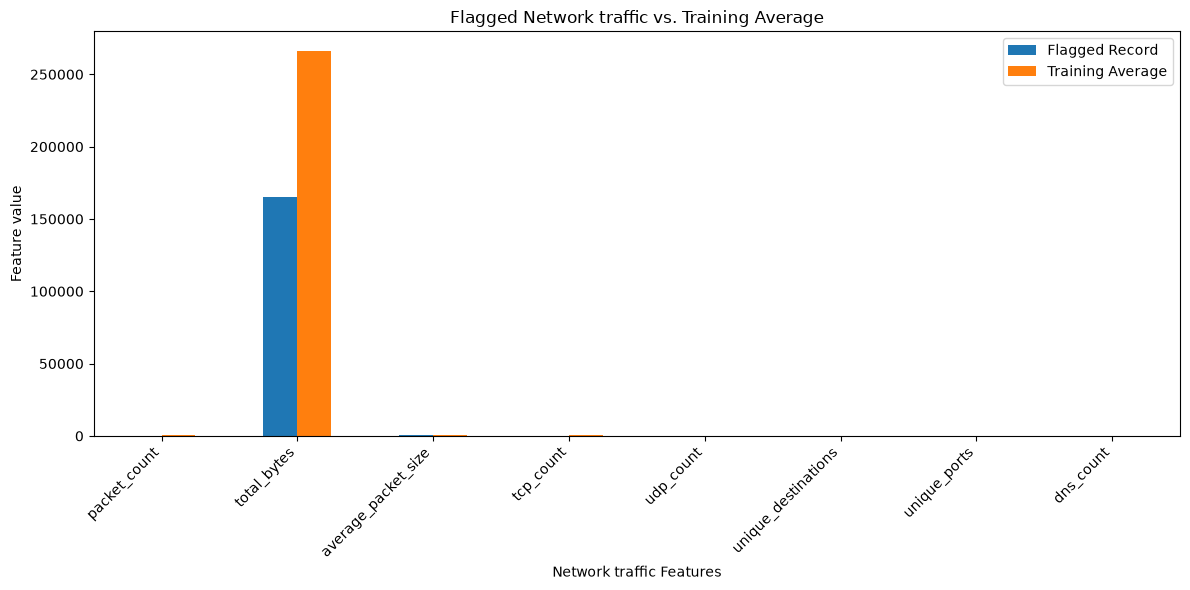

In [16]:
# ============================================================
# Step 11: Visualize the flagged record against training means
# ============================================================

import matplotlib.pyplot as plt

# Create a chart comparing the flagged record with the training average.
comparison[["flagged_value", "training_mean"]].plot(
    kind="bar",
    figsize=(12, 6)
)

# Add a descriptive title and axis labels.
plt.title("Flagged Network traffic vs. Training Average")
plt.xlabel("Network traffic Features")
plt.ylabel("Feature value")

# Rotate the feature names so they are easier to read.
plt.xticks(rotation = 45, ha="right")

# Display the legend and adjust the layout.
plt.legend(["Flagged Record", "Training Average"])
plt.tight_layout()

# Display the chart.
plt.show()



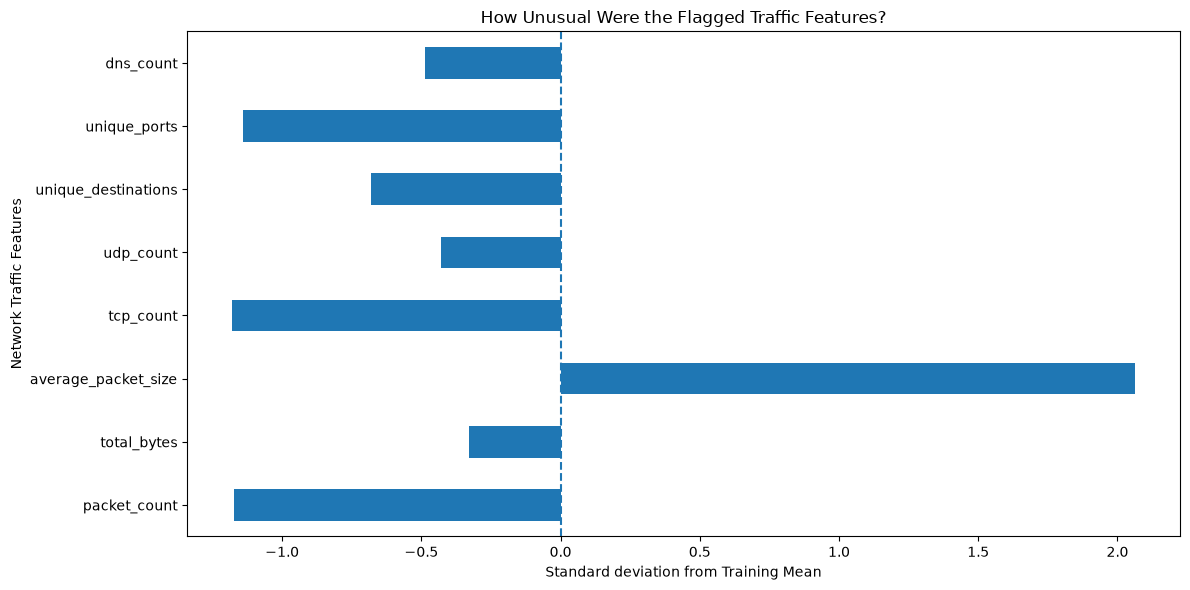

In [17]:
# =============================================================
# Step 12: Visualize standard deviations from the training mean
# =============================================================

# Create a horizontal bar chart using the standard-deviation nvalues.
comparison["standard_deviations_from_mean"].plot(
    kind="barh",
    figsize=(12, 6)
)

# Add a vertical reference line at zero (the training average).
plt.axvline(x=0, linestyle="--")

# Add a descriptive title and axis labels.
plt.title("How Unusual Were the Flagged Traffic Features?")
plt.xlabel("Standard deviation from Training Mean")
plt.ylabel("Network Traffic Features")

# Add spacing so labels and the title are not cut off.
plt.tight_layout()

# Display the chart.
plt.show()



In [18]:
# ============================================================
# Step 13: Identify the timestamp of the flagged record
# ============================================================

# Retrieve the timestamp of the first flagged record.
flagged_timestamp = anomalies["minute"].iloc[0]

# Display the timestamp we want to investigate.
print("Flagged traffic timestamp:", flagged_timestamp)

# Display the device that generated the flagged traffic.
print("Device IP:", anomalies["device_ip"].iloc[0])

Flagged traffic timestamp: 10/6/2026 19:35
Device IP: 192.168.50.10
